libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Upload dataset

In [2]:
from google.colab import files

uploaded = files.upload()

Saving AB_NYC_2019.csv to AB_NYC_2019.csv
Saving New_York_City_.png to New_York_City_.png


Load the dataset

In [3]:
df = pd.read_csv("AB_NYC_2019.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Initial Data Quality Audit

In [4]:
# ==========================================
# INITIAL DATA QUALITY AUDIT
# ==========================================

print("=" * 60)
print("1. DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_report)

print("\n" + "=" * 60)
print("3. DUPLICATE RECORDS")
print("=" * 60)

print("Total duplicate rows:", df.duplicated().sum())
print("Duplicate Listing IDs:", df["id"].duplicated().sum())

print("\n" + "=" * 60)
print("4. STATISTICAL SUMMARY")
print("=" * 60)

display(df.describe())

print("\n" + "=" * 60)
print("5. UNIQUE VALUES")
print("=" * 60)

print("Unique Listings:", df["id"].nunique())
print("Unique Hosts:", df["host_id"].nunique())
print("Unique Neighbourhood Groups:",
      df["neighbourhood_group"].nunique())
print("Unique Room Types:", df["room_type"].nunique())

print("\n" + "=" * 60)
print("6. DATASET DATE RANGE")
print("=" * 60)

df["last_review"] = pd.to_datetime(
    df["last_review"], errors="coerce"
)

print("Earliest Review:", df["last_review"].min())
print("Latest Review:", df["last_review"].max())

print("\nINITIAL DATA QUALITY AUDIT COMPLETED!")

1. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_revi

,Missing Values,Missing Percentage
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00



3. DUPLICATE RECORDS
Total duplicate rows: 0
Duplicate Listing IDs: 0

4. STATISTICAL SUMMARY


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000



5. UNIQUE VALUES
Unique Listings: 48895
Unique Hosts: 37457
Unique Neighbourhood Groups: 5
Unique Room Types: 3

6. DATASET DATE RANGE
Earliest Review: 2011-03-28 00:00:00
Latest Review: 2019-07-08 00:00:00

INITIAL DATA QUALITY AUDIT COMPLETED!


Investigate data-quality issues

In [5]:
# ==========================================
# INVESTIGATION OF DATA QUALITY ISSUES
# ==========================================

print("1. CHECK MISSING REVIEW RELATIONSHIP")

print("\nMissing last_review:")
print(df["last_review"].isnull().sum())

print("\nMissing reviews_per_month:")
print(df["reviews_per_month"].isnull().sum())

print("\nReview count for records with missing last_review:")
display(
    df.loc[
        df["last_review"].isnull(),
        "number_of_reviews"
    ].value_counts().head()
)

print("\n2. CHECK ZERO AND NEGATIVE PRICES")

print("Zero-price listings:", (df["price"] == 0).sum())
print("Negative-price listings:", (df["price"] < 0).sum())

print("\nSample zero-price records:")
display(df[df["price"] == 0].head(10))

print("\n3. CHECK UNUSUAL MINIMUM NIGHTS")

print("Listings with minimum_nights > 365:",
      (df["minimum_nights"] > 365).sum())

display(
    df[df["minimum_nights"] > 365]
    [["id", "name", "minimum_nights", "price"]]
    .head(10)
)

print("\n4. CHECK PRICE DISTRIBUTION")

display(
    df["price"].quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
    )
)

print("\n5. CHECK MISSING NAMES")

print("Missing listing names:", df["name"].isnull().sum())
print("Missing host names:", df["host_name"].isnull().sum())

print("\n6. CHECK ROOM TYPES")

display(df["room_type"].value_counts())

print("\nDATA QUALITY INVESTIGATION COMPLETED!")

1. CHECK MISSING REVIEW RELATIONSHIP

Missing last_review:
10052

Missing reviews_per_month:
10052

Review count for records with missing last_review:


,count
number_of_reviews,
0,10052



2. CHECK ZERO AND NEGATIVE PRICES
Zero-price listings: 11
Negative-price listings: 0

Sample zero-price records:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",8993084,Kimberly,Brooklyn,Bedford-Stuyvesant,40.69023,-73.95428,Private room,0,4,1,2018-01-06,0.05,4,28
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,131697576,Anisha,Bronx,East Morrisania,40.83296,-73.88668,Private room,0,2,55,2019-06-24,2.56,4,127
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",15787004,Martial Loft,Brooklyn,Bushwick,40.69467,-73.92433,Private room,0,2,16,2019-05-18,0.71,5,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",1641537,Lauren,Brooklyn,Greenpoint,40.72462,-73.94072,Private room,0,2,12,2017-10-27,0.53,2,0
25778,20624541,Modern apartment in the heart of Williamsburg,10132166,Aymeric,Brooklyn,Williamsburg,40.70838,-73.94645,Entire home/apt,0,5,3,2018-01-02,0.15,1,73
25794,20639628,Spacious comfortable master bedroom with nice ...,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68173,-73.91342,Private room,0,1,93,2019-06-15,4.28,6,176
25795,20639792,Contemporary bedroom in brownstone with nice view,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68279,-73.91170,Private room,0,1,95,2019-06-21,4.37,6,232
25796,20639914,Cozy yet spacious private brownstone bedroom,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68258,-73.91284,Private room,0,1,95,2019-06-23,4.35,6,222
26259,20933849,the best you can find,13709292,Qiuchi,Manhattan,Murray Hill,40.75091,-73.97597,Entire home/apt,0,3,0,NaT,NaN,1,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,101970559,Sergii,Brooklyn,Bushwick,40.69211,-73.90670,Shared room,0,30,2,2019-06-22,0.11,6,333



3. CHECK UNUSUAL MINIMUM NIGHTS
Listings with minimum_nights > 365: 14


,id,name,minimum_nights,price
1305,568684,800sqft apartment with huge terrace,370,115
2854,1615764,NaN,1000,400
5767,4204302,Prime W. Village location 1 bdrm,1250,180
7355,5431845,Beautiful Fully Furnished 1 bed/bth,500,134
8014,6169897,Wonderful Large 1 bedroom,500,75
10829,8341919,Brand New Luxury Apt Lease Takeover,480,199
11193,8668115,Zen Room in Crown Heights Brooklyn,500,50
13404,10053943,Historic Designer 2 Bed. Apartment,999,99
14285,11096888,Peaceful apartment close to F/G,500,45
15946,12888849,"Bright Luxury Studio, Central Loc.",366,250



4. CHECK PRICE DISTRIBUTION


,price
0.00,0.0
0.25,69.0
0.50,106.0
0.75,175.0
0.90,269.0
0.95,355.0
0.99,799.0
1.00,10000.0



5. CHECK MISSING NAMES
Missing listing names: 16
Missing host names: 21

6. CHECK ROOM TYPES


,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160



DATA QUALITY INVESTIGATION COMPLETED!


Visualize missing values

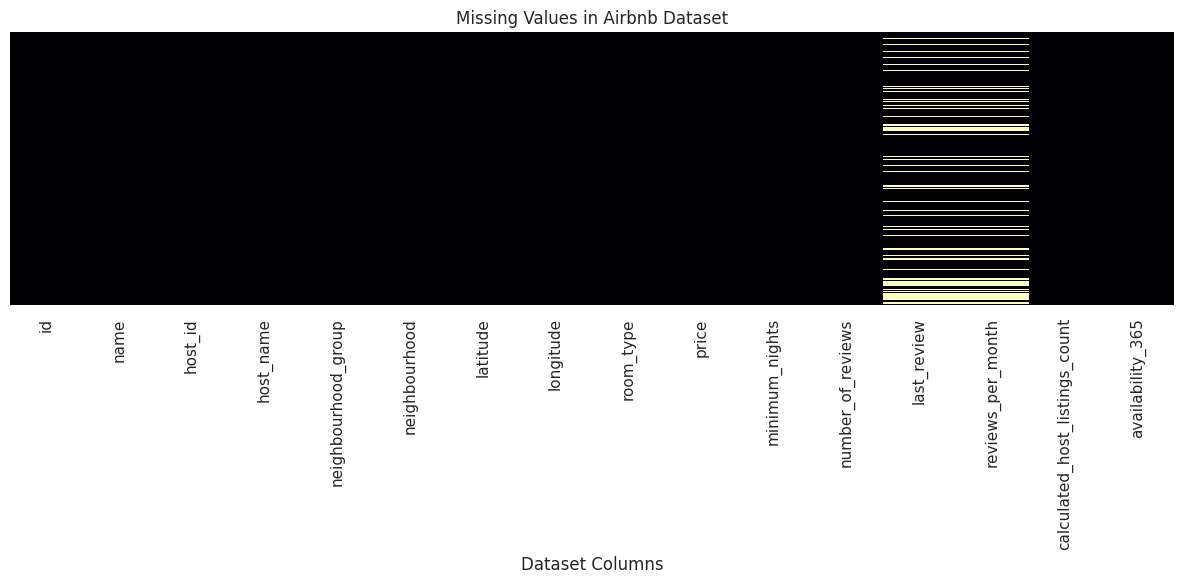

In [6]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='magma'
)

plt.title("Missing Values in Airbnb Dataset")
plt.xlabel("Dataset Columns")
plt.tight_layout()
plt.show()


Check duplicate records

In [7]:

# ============================================
# STEP 4.3: DUPLICATE RECORD INVESTIGATION
# ============================================

print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate listing IDs:", df['id'].duplicated().sum())

print("\nUnique listing IDs:", df['id'].nunique())
print("Total records:", len(df))


Exact duplicate rows: 0
Duplicate listing IDs: 0

Unique listing IDs: 48895
Total records: 48895


Check zero and negative prices

In [8]:

# ============================================
# STEP 4.4: PRICE VALIDATION
# ============================================

print("Zero-price listings:", (df['price'] == 0).sum())

print("Negative-price listings:", (df['price'] < 0).sum())

print("\nPrice statistics:")
display(df['price'].describe())


Zero-price listings: 11
Negative-price listings: 0

Price statistics:


,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


Check unusual minimum nights

In [9]:

# ============================================
# STEP 4.5: MINIMUM NIGHT VALIDATION
# ============================================

unusual_nights = df[df['minimum_nights'] > 365]

print(
    "Listings with minimum nights above 365:",
    len(unusual_nights)
)

display(
    unusual_nights[
        ['id', 'name', 'minimum_nights', 'price']
    ].head(20)
)


Listings with minimum nights above 365: 14


,id,name,minimum_nights,price
1305,568684,800sqft apartment with huge terrace,370,115
2854,1615764,NaN,1000,400
5767,4204302,Prime W. Village location 1 bdrm,1250,180
7355,5431845,Beautiful Fully Furnished 1 bed/bth,500,134
8014,6169897,Wonderful Large 1 bedroom,500,75
10829,8341919,Brand New Luxury Apt Lease Takeover,480,199
11193,8668115,Zen Room in Crown Heights Brooklyn,500,50
13404,10053943,Historic Designer 2 Bed. Apartment,999,99
14285,11096888,Peaceful apartment close to F/G,500,45
15946,12888849,"Bright Luxury Studio, Central Loc.",366,250


Check invalid geographical coordinates

In [10]:

# ============================================
# STEP 4.6: GEOGRAPHICAL VALIDATION
# ============================================

invalid_coordinates = df[
    ~df['latitude'].between(-90, 90) |
    ~df['longitude'].between(-180, 180)
]

print("Invalid coordinates:", len(invalid_coordinates))

print("\nLatitude range:")
print(df['latitude'].min(), df['latitude'].max())

print("\nLongitude range:")
print(df['longitude'].min(), df['longitude'].max())


Invalid coordinates: 0

Latitude range:
40.49979 40.91306

Longitude range:
-74.24442 -73.71299


Check missing names and room types

In [11]:

# ============================================
# STEP 4.7: CATEGORICAL DATA VALIDATION
# ============================================

print("Missing listing names:", df['name'].isnull().sum())

print("Missing host names:", df['host_name'].isnull().sum())

print("\nRoom type distribution:")
print(df['room_type'].value_counts())

print("\nNeighbourhood groups:")
print(df['neighbourhood_group'].value_counts())


Missing listing names: 16
Missing host names: 21

Room type distribution:
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

Neighbourhood groups:
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


5.1 Create cleaned dataset

In [12]:

# ============================================
# STEP 5.1: CREATE CLEAN DATASET
# ============================================

df_clean = df.copy()

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Handle missing listing names
df_clean['name'] = df_clean['name'].fillna(
    'Unknown Listing'
)

# Handle missing host names
df_clean['host_name'] = df_clean['host_name'].fillna(
    'Unknown Host'
)

# Handle missing monthly reviews
df_clean['reviews_per_month'] = (
    df_clean['reviews_per_month'].fillna(0)
)

# Convert last_review to datetime
df_clean['last_review'] = pd.to_datetime(
    df_clean['last_review'],
    errors='coerce'
)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df_clean.shape)


Data cleaning completed!
Cleaned dataset shape: (48895, 16)


5.2 Remove invalid records from the analysis dataset

In [13]:

# ============================================
# STEP 5.2: CREATE ANALYSIS DATASET
# ============================================

df_analysis = df_clean[
    (df_clean['price'] > 0) &
    (df_clean['minimum_nights'] > 0) &
    (df_clean['latitude'].between(-90, 90)) &
    (df_clean['longitude'].between(-180, 180))
].copy()

print("Original records:", len(df))

print("Cleaned records:", len(df_clean))

print("Analysis-ready records:", len(df_analysis))

print(
    "Records excluded from analysis:",
    len(df_clean) - len(df_analysis)
)


Original records: 48895
Cleaned records: 48895
Analysis-ready records: 48884
Records excluded from analysis: 11


5.3 Create additional analytical columns

In [14]:

# ============================================
# STEP 5.3: FEATURE ENGINEERING
# ============================================

# Extract review year
df_analysis['review_year'] = (
    df_analysis['last_review'].dt.year
)

# Create price categories
df_analysis['price_category'] = pd.cut(
    df_analysis['price'],
    bins=[0, 100, 200, 500, float('inf')],
    labels=[
        'Budget',
        'Moderate',
        'Premium',
        'Luxury'
    ],
    right=True
)

# Flag unusually long minimum stays
df_analysis['long_stay_flag'] = (
    df_analysis['minimum_nights'] > 365
)

# Create a host activity category
df_analysis['host_activity'] = pd.cut(
    df_analysis['calculated_host_listings_count'],
    bins=[0, 1, 5, 20, float('inf')],
    labels=[
        'Single Listing',
        'Small Host',
        'Medium Host',
        'Large Host'
    ]
)

print("Feature engineering completed!")

display(df_analysis.head())


Feature engineering completed!


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,review_year,price_category,long_stay_flag,host_activity
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365,2018.0,Moderate,False,Medium Host
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355,2019.0,Premium,False,Small Host
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,0.00,1,365,NaN,Moderate,False,Single Listing
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194,2019.0,Budget,False,Single Listing
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0,2018.0,Budget,False,Single Listing


Verify cleaning

In [15]:

# ============================================
# STEP 5.4: CLEANING VERIFICATION
# ============================================

print("Remaining missing values:")
print(df_clean.isnull().sum())

print("\nZero-price records in analysis dataset:")
print((df_analysis['price'] == 0).sum())

print("\nNegative-price records in analysis dataset:")
print((df_analysis['price'] < 0).sum())

print("\nExact duplicates after cleaning:")
print(df_clean.duplicated().sum())


Remaining missing values:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Zero-price records in analysis dataset:
0

Negative-price records in analysis dataset:
0

Exact duplicates after cleaning:
0


6. Exploratory Data Analysis (EDA)


Step 6.1: Overall Airbnb statistics

In [16]:

# ============================================
# STEP 6.1: OVERALL STATISTICS
# ============================================

print("AIRBNB NYC DATA ANALYSIS")
print("=" * 40)

print("Total listings:", len(df_analysis))

print(
    "Total neighbourhoods:",
    df_analysis['neighbourhood'].nunique()
)

print(
    "Total neighbourhood groups:",
    df_analysis['neighbourhood_group'].nunique()
)

print(
    "Total unique hosts:",
    df_analysis['host_id'].nunique()
)

print(
    "Average price: $",
    round(df_analysis['price'].mean(), 2)
)

print(
    "Median price: $",
    round(df_analysis['price'].median(), 2)
)

print(
    "Average minimum nights:",
    round(df_analysis['minimum_nights'].mean(), 2)
)

print(
    "Total reviews:",
    df_analysis['number_of_reviews'].sum()
)


AIRBNB NYC DATA ANALYSIS
Total listings: 48884
Total neighbourhoods: 221
Total neighbourhood groups: 5
Total unique hosts: 37455
Average price: $ 152.76
Median price: $ 106.0
Average minimum nights: 7.03
Total reviews: 1137628


Step 6.2: Listings by neighbourhood group

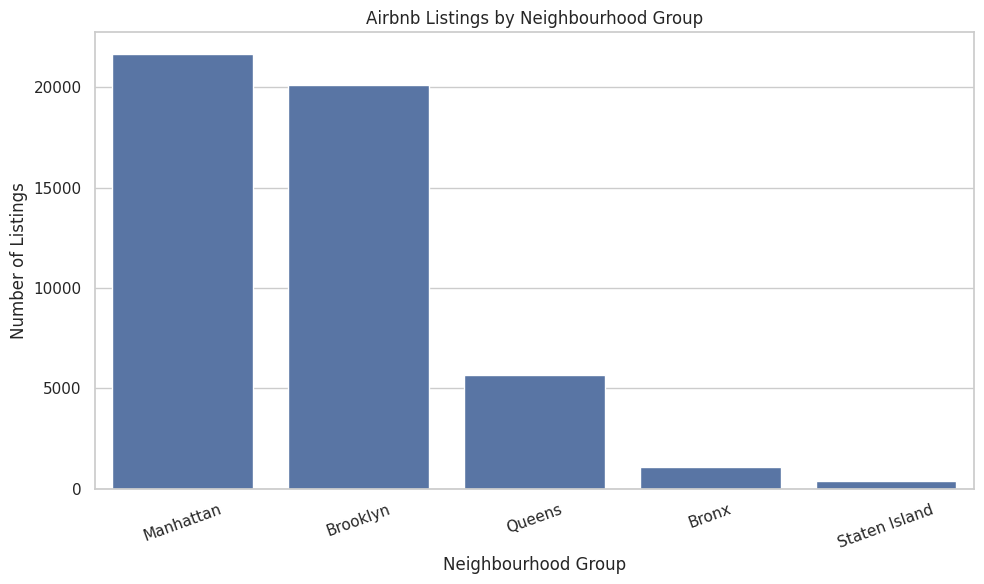

,count
neighbourhood_group,
Manhattan,21660
Brooklyn,20095
Queens,5666
Bronx,1090
Staten Island,373


In [17]:

# ============================================
# STEP 6.2: LISTINGS BY NEIGHBOURHOOD GROUP
# ============================================

borough_counts = (
    df_analysis['neighbourhood_group']
    .value_counts()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=borough_counts.index,
    y=borough_counts.values
)

plt.title("Airbnb Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

display(borough_counts)


Step 6.3: Room type distribution


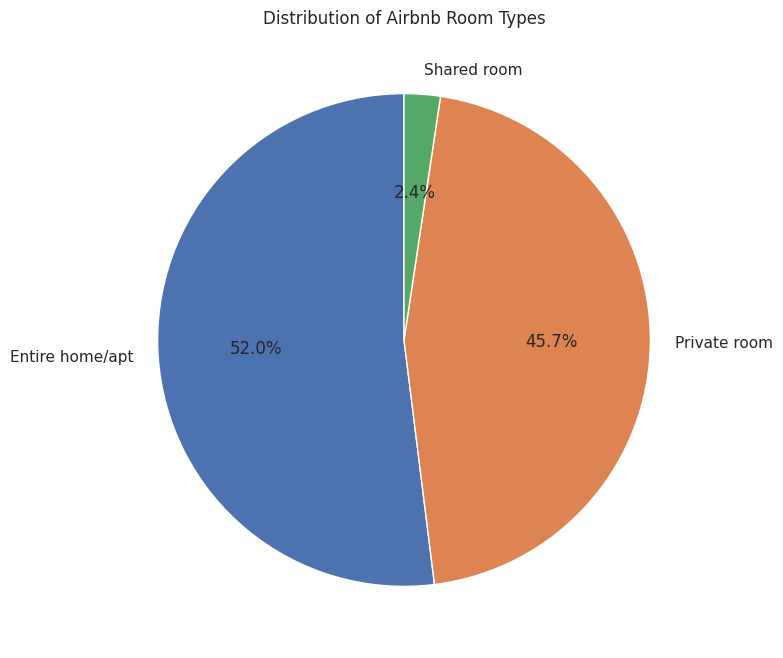

,count
room_type,
Entire home/apt,25407
Private room,22319
Shared room,1158


In [18]:

# ============================================
# STEP 6.3: ROOM TYPE DISTRIBUTION
# ============================================

room_counts = df_analysis['room_type'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    room_counts.values,
    labels=room_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Airbnb Room Types")

plt.show()

display(room_counts)


6.4: Price distribution

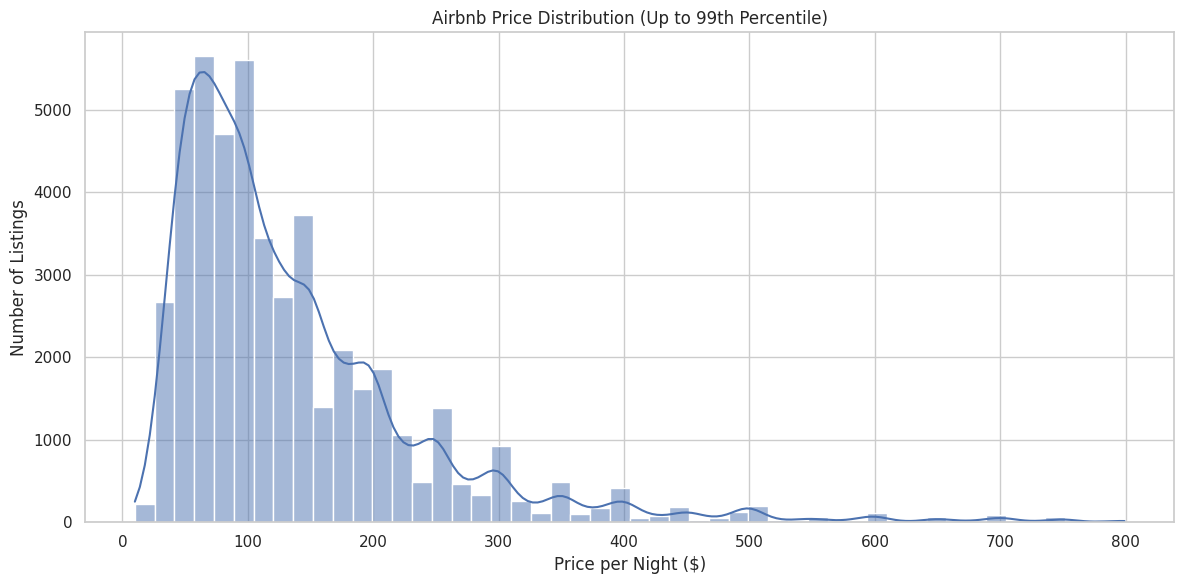

99th percentile price: 799.0
Overall median price: 106.0


In [19]:

# ============================================
# STEP 6.4: PRICE DISTRIBUTION
# ============================================

price_99 = df_analysis['price'].quantile(0.99)

price_visual = df_analysis[
    df_analysis['price'] <= price_99
]

plt.figure(figsize=(12, 6))

sns.histplot(
    price_visual['price'],
    bins=50,
    kde=True
)

plt.title("Airbnb Price Distribution (Up to 99th Percentile)")
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

print("99th percentile price:", price_99)

print("Overall median price:", df_analysis['price'].median())


6.5: Average price by neighbourhood group

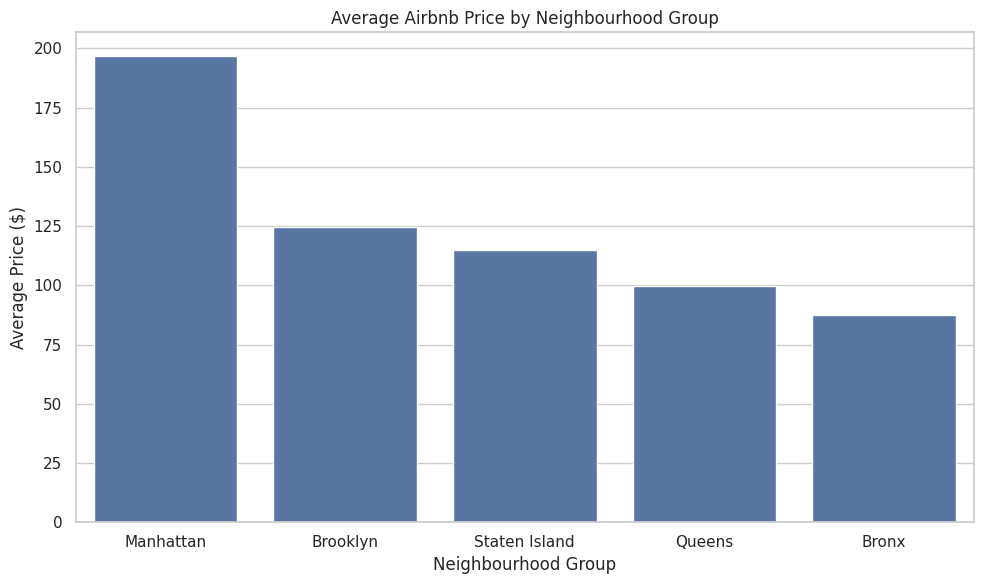

,price
neighbourhood_group,
Manhattan,196.884903
Brooklyn,124.438915
Staten Island,114.812332
Queens,99.517649
Bronx,87.577064


In [20]:

# ============================================
# STEP 6.5: AVERAGE PRICE BY BOROUGH
# ============================================

borough_price = (
    df_analysis.groupby('neighbourhood_group')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=borough_price.index,
    y=borough_price.values
)

plt.title("Average Airbnb Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Price ($)")

plt.tight_layout()
plt.show()

display(borough_price)


6.6: Price comparison by room type

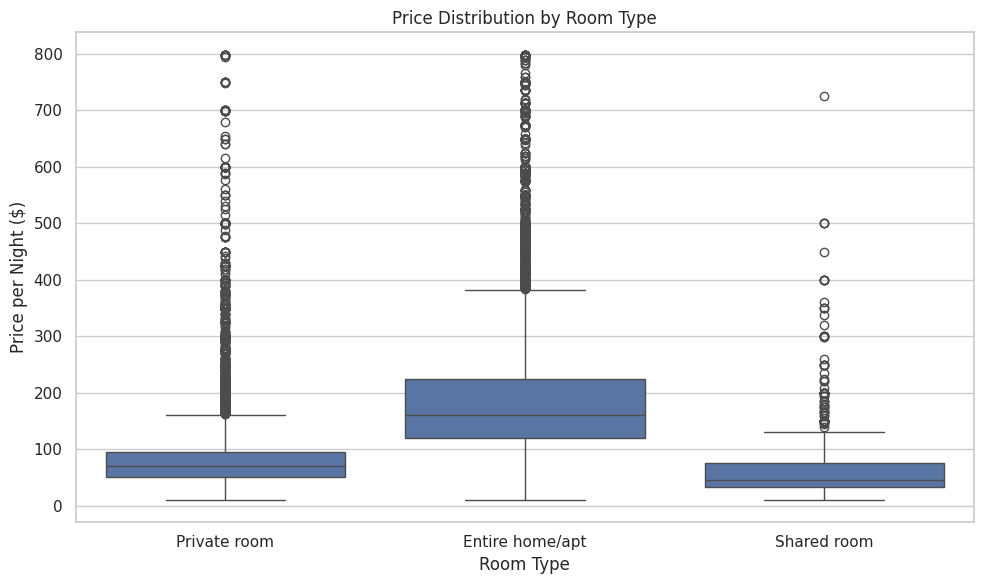

Median price by room type:


,price
room_type,
Entire home/apt,160.0
Private room,70.0
Shared room,45.0


In [21]:

# ============================================
# STEP 6.6: PRICE BY ROOM TYPE
# ============================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=price_visual,
    x='room_type',
    y='price'
)

plt.title("Price Distribution by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price per Night ($)")

plt.tight_layout()
plt.show()

print("Median price by room type:")

display(
    df_analysis.groupby('room_type')['price']
    .median()
    .sort_values(ascending=False)
)


6.7: Top 10 neighbourhoods by listing count

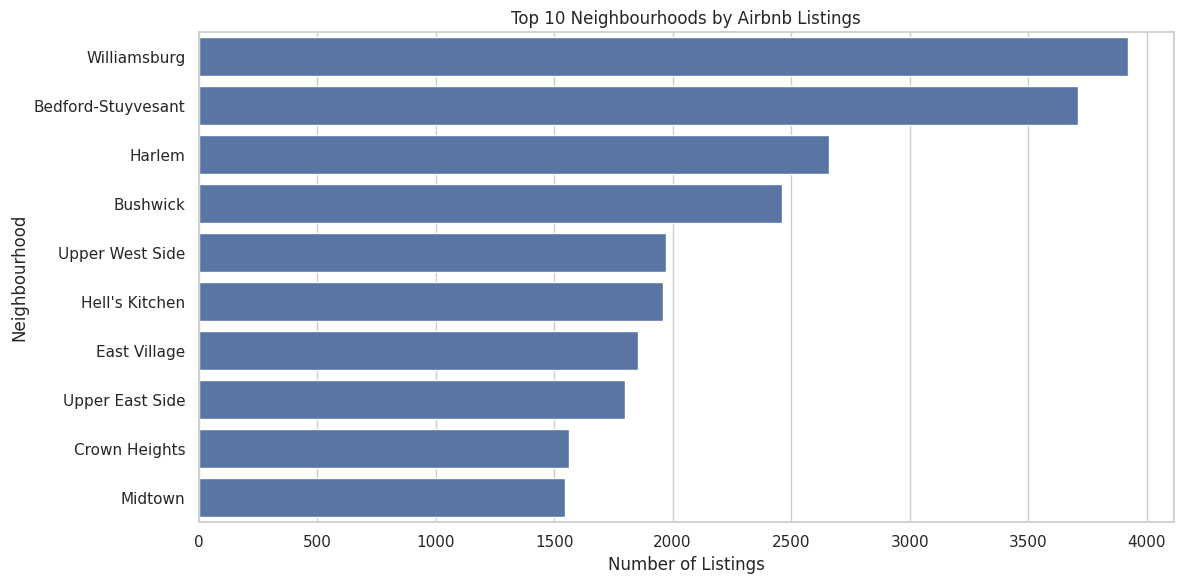

,count
neighbourhood,
Williamsburg,3919
Bedford-Stuyvesant,3710
Harlem,2658
Bushwick,2462
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564


In [22]:

# ============================================
# STEP 6.7: TOP 10 NEIGHBOURHOODS
# ============================================

top_neighbourhoods = (
    df_analysis['neighbourhood']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_neighbourhoods.values,
    y=top_neighbourhoods.index
)

plt.title("Top 10 Neighbourhoods by Airbnb Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")

plt.tight_layout()
plt.show()

display(top_neighbourhoods)


6.8: Minimum nights analysis

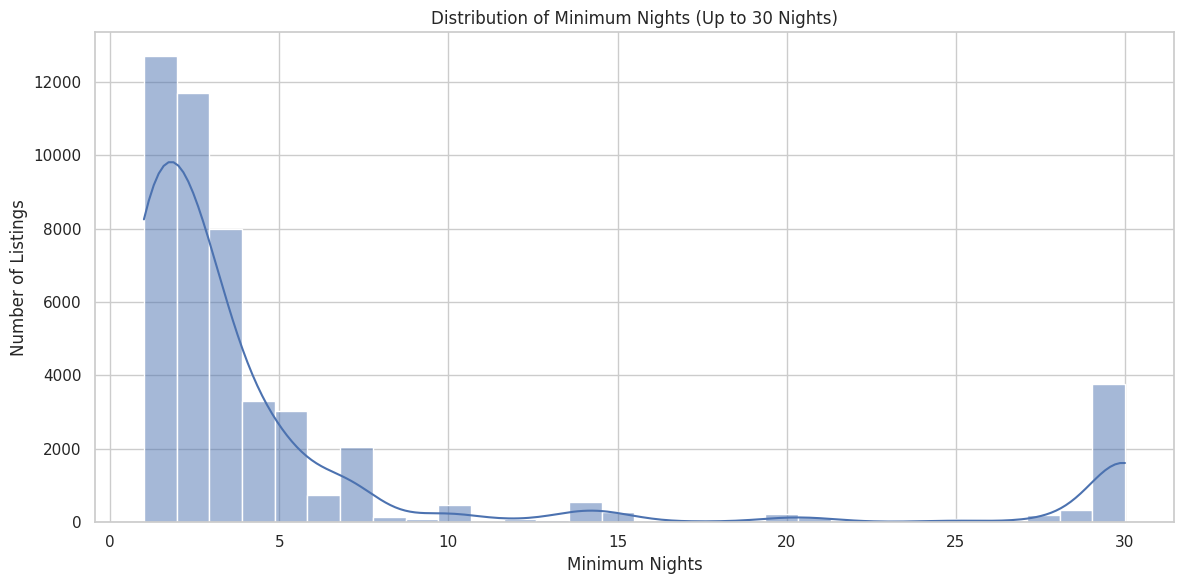

Median minimum nights:
3.0
Listings requiring more than 365 nights:
14


In [23]:

# ============================================
# STEP 6.8: MINIMUM NIGHT ANALYSIS
# ============================================

nights_visual = df_analysis[
    df_analysis['minimum_nights'] <= 30
]

plt.figure(figsize=(12, 6))

sns.histplot(
    nights_visual['minimum_nights'],
    bins=30,
    kde=True
)

plt.title("Distribution of Minimum Nights (Up to 30 Nights)")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

print("Median minimum nights:")
print(df_analysis['minimum_nights'].median())

print("Listings requiring more than 365 nights:")
print(df_analysis['long_stay_flag'].sum())


6.9: Reviews analysis

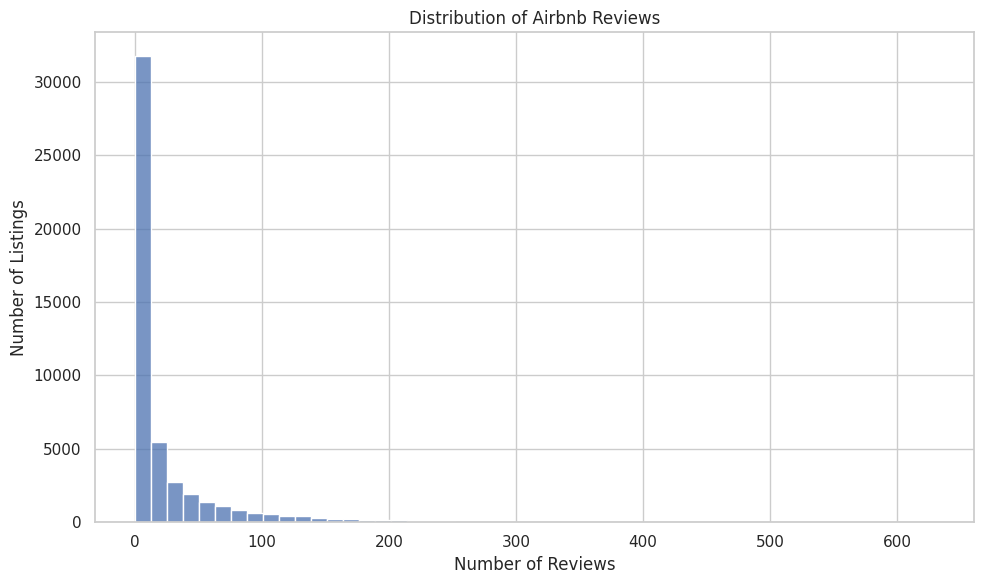

Average number of reviews:
23.27199083544718
Maximum number of reviews:
629
Listings with zero reviews:
10051


In [24]:

# ============================================
# STEP 6.9: REVIEWS ANALYSIS
# ============================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_analysis,
    x='number_of_reviews',
    bins=50
)

plt.title("Distribution of Airbnb Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

print("Average number of reviews:")
print(df_analysis['number_of_reviews'].mean())

print("Maximum number of reviews:")
print(df_analysis['number_of_reviews'].max())

print("Listings with zero reviews:")
print(
    (df_analysis['number_of_reviews'] == 0).sum()
)


6.10: Reviews over time

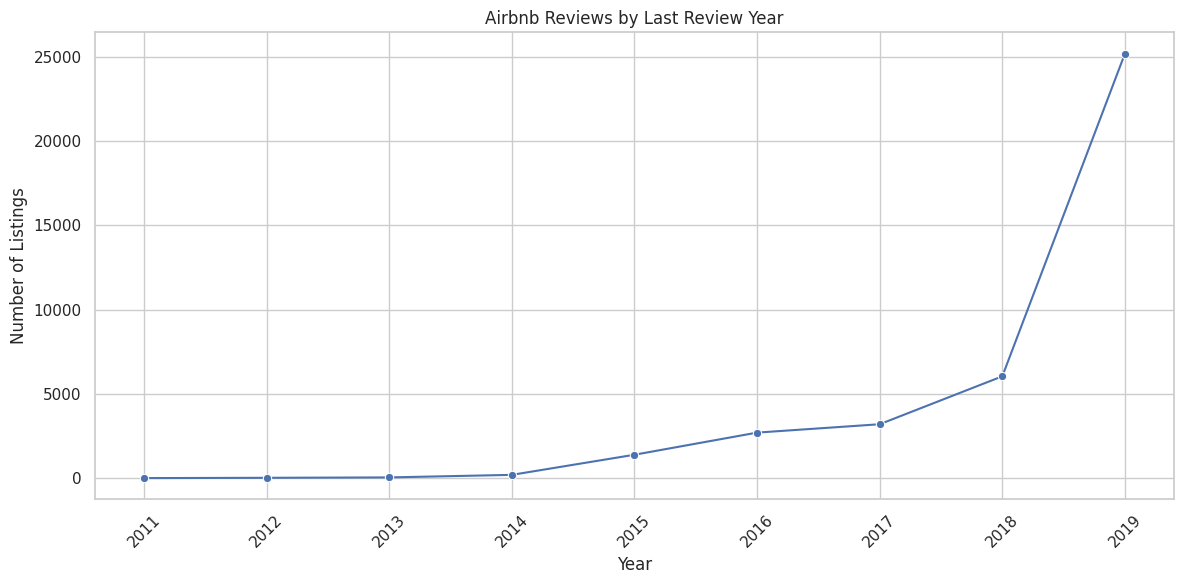

,count
review_year,
2011,7
2012,25
2013,48
2014,199
2015,1393
2016,2707
2017,3204
2018,6048
2019,25202


In [25]:

# ============================================
# STEP 6.10: REVIEWS OVER TIME
# ============================================

review_year_counts = (
    df_analysis['review_year']
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=review_year_counts.index,
    y=review_year_counts.values,
    marker='o'
)

plt.title("Airbnb Reviews by Last Review Year")
plt.xlabel("Year")
plt.ylabel("Number of Listings")

plt.xticks(review_year_counts.index, rotation=45)

plt.tight_layout()
plt.show()

display(review_year_counts)


6.11: Availability analysis

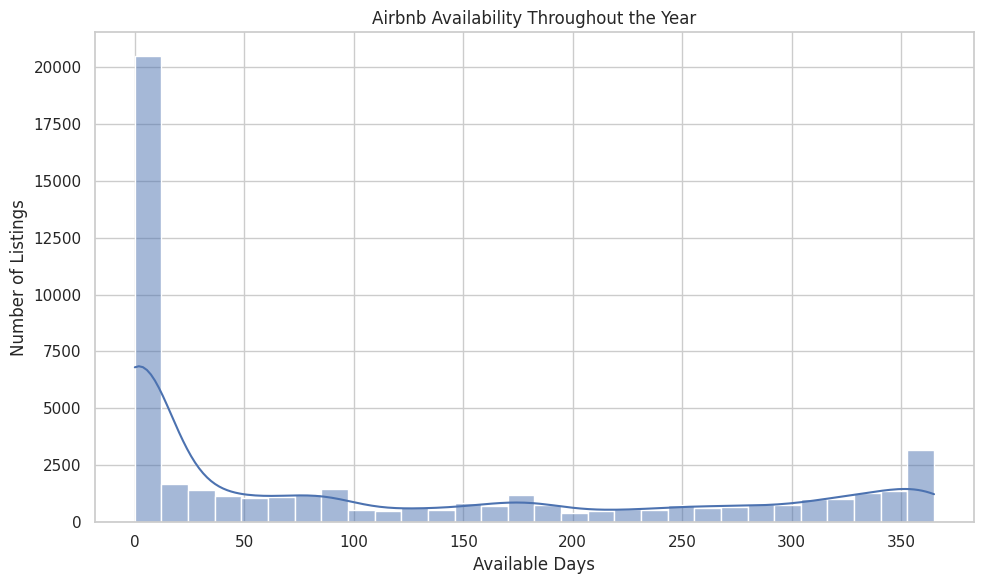

Average availability:
112.77949840438589
Median availability:
45.0


In [26]:

# ============================================
# STEP 6.11: AVAILABILITY ANALYSIS
# ============================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df_analysis['availability_365'],
    bins=30,
    kde=True
)

plt.title("Airbnb Availability Throughout the Year")
plt.xlabel("Available Days")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

print("Average availability:")
print(df_analysis['availability_365'].mean())

print("Median availability:")
print(df_analysis['availability_365'].median())


6.12: Top hosts by number of listings

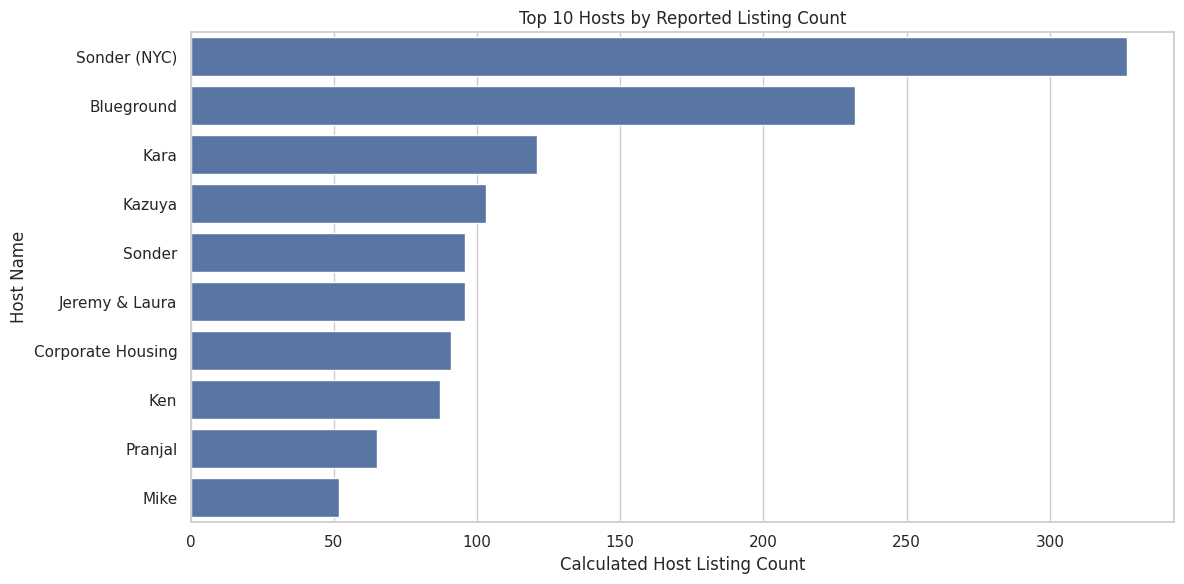

,calculated_host_listings_count
host_name,
Sonder (NYC),327
Blueground,232
Kara,121
Kazuya,103
Sonder,96
Jeremy & Laura,96
Corporate Housing,91
Ken,87
Pranjal,65


In [27]:

# ============================================
# STEP 6.12: TOP AIRBNB HOSTS
# ============================================

top_hosts = (
    df_analysis.groupby('host_name')
    ['calculated_host_listings_count']
    .max()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_hosts.values,
    y=top_hosts.index
)

plt.title("Top 10 Hosts by Reported Listing Count")
plt.xlabel("Calculated Host Listing Count")
plt.ylabel("Host Name")

plt.tight_layout()
plt.show()

display(top_hosts)


Advanced analysis
7.1: Correlation heatmap

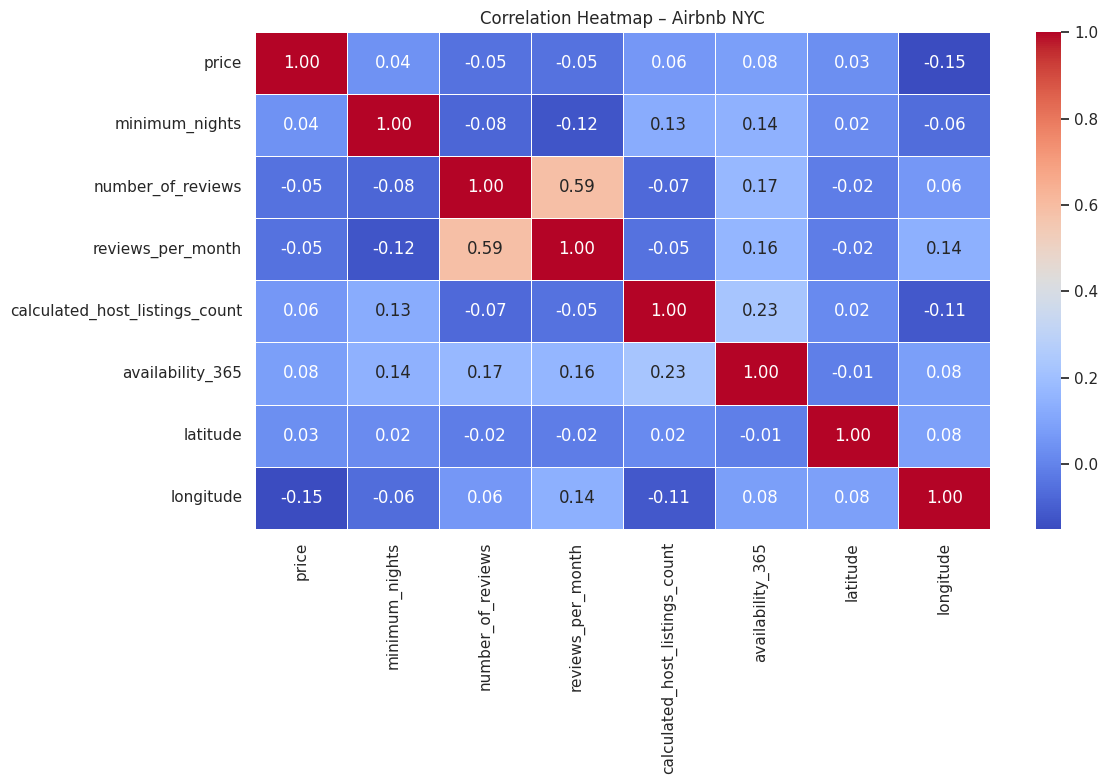

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
price,1.000000,0.042805,-0.047926,-0.050531,0.057462,0.081847,0.033899,-0.149954
minimum_nights,0.042805,1.000000,-0.080080,-0.124870,0.127962,0.144275,0.024893,-0.062772
number_of_reviews,-0.047926,-0.080080,1.000000,0.589311,-0.072385,0.171975,-0.015357,0.059015
reviews_per_month,-0.050531,-0.124870,0.589311,1.000000,-0.047322,0.163664,-0.018719,0.138435
calculated_host_listings_count,0.057462,0.127962,-0.072385,-0.047322,1.000000,0.225712,0.019518,-0.114715
availability_365,0.081847,0.144275,0.171975,0.163664,0.225712,1.000000,-0.010942,0.082669
latitude,0.033899,0.024893,-0.015357,-0.018719,0.019518,-0.010942,1.000000,0.084830
longitude,-0.149954,-0.062772,0.059015,0.138435,-0.114715,0.082669,0.084830,1.000000


In [28]:

# ============================================
# STEP 7.1: CORRELATION HEATMAP
# ============================================

numeric_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
    'latitude',
    'longitude'
]

correlation = df_analysis[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap – Airbnb NYC")

plt.tight_layout()
plt.show()

display(correlation)


7.2: Price versus number of reviews

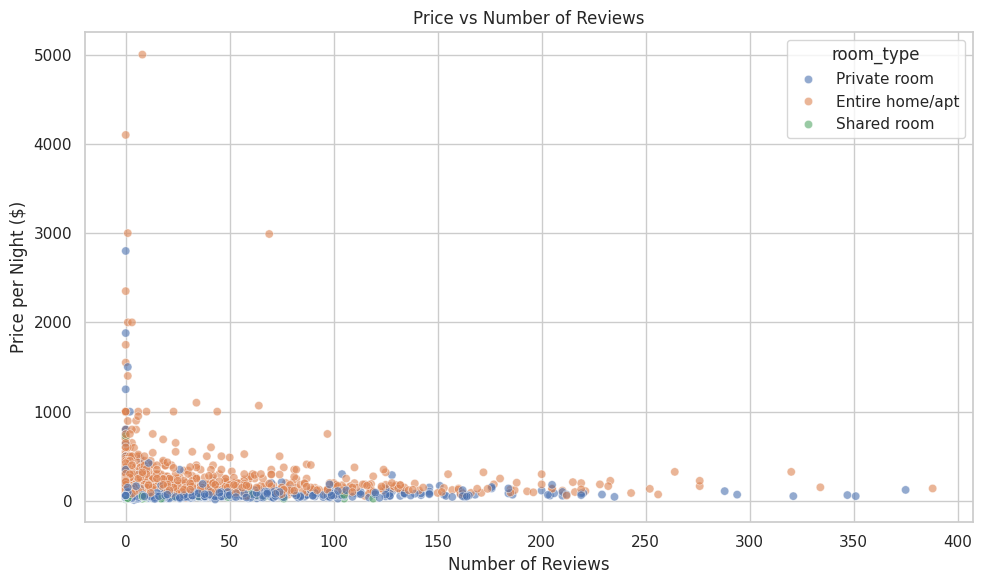

In [29]:

# ============================================
# STEP 7.2: PRICE VS NUMBER OF REVIEWS
# ============================================

sample_data = df_analysis.sample(
    n=min(3000, len(df_analysis)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_data,
    x='number_of_reviews',
    y='price',
    hue='room_type',
    alpha=0.6
)

plt.title("Price vs Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Price per Night ($)")

plt.tight_layout()
plt.show()


7.3: Geographical distribution of Airbnb listings

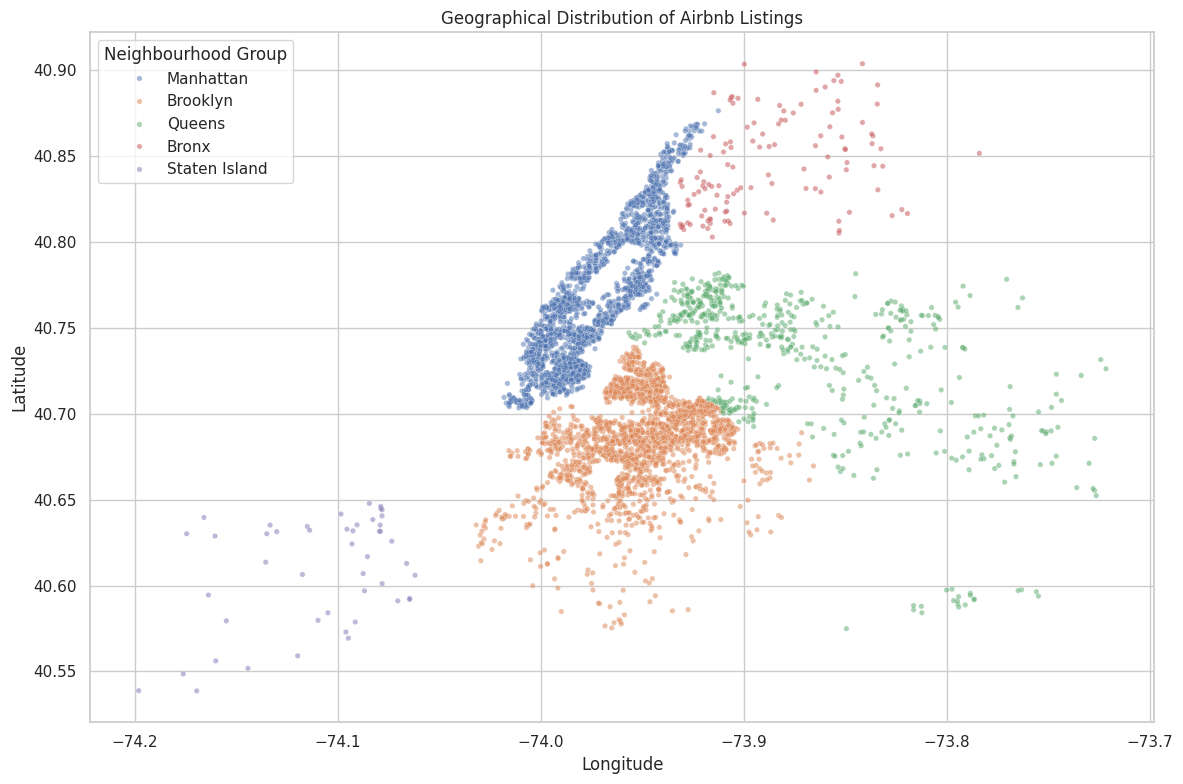

In [30]:

# ============================================
# STEP 7.3: GEOGRAPHICAL DISTRIBUTION
# ============================================

geo_sample = df_analysis.sample(
    n=min(5000, len(df_analysis)),
    random_state=42
)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=geo_sample,
    x='longitude',
    y='latitude',
    hue='neighbourhood_group',
    alpha=0.5,
    s=15
)

plt.title("Geographical Distribution of Airbnb Listings")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(title="Neighbourhood Group")

plt.tight_layout()
plt.show()


7.4: Price category distribution

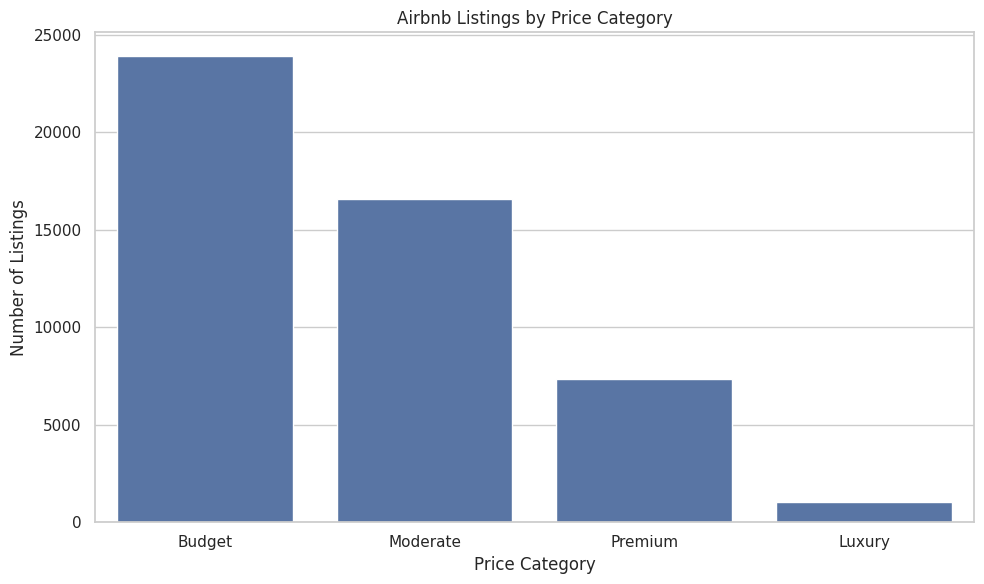

,count
price_category,
Budget,23917
Moderate,16583
Premium,7340
Luxury,1044


In [31]:

# ============================================
# STEP 7.4: PRICE CATEGORY DISTRIBUTION
# ============================================

category_counts = (
    df_analysis['price_category']
    .value_counts()
    .reindex(['Budget', 'Moderate', 'Premium', 'Luxury'])
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Airbnb Listings by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

display(category_counts)


Final validation and quality checks
8.1: Run validation tests

In [32]:

# ============================================
# STEP 8.1: FINAL DATA VALIDATION
# ============================================

print("FINAL DATA VALIDATION")
print("=" * 45)

# Check duplicate listing IDs
print(
    "Duplicate IDs:",
    df_clean['id'].duplicated().sum()
)

# Check invalid prices in analysis dataset
print(
    "Invalid prices:",
    (df_analysis['price'] <= 0).sum()
)

# Check invalid minimum nights
print(
    "Invalid minimum nights:",
    (df_analysis['minimum_nights'] <= 0).sum()
)

# Check missing listing names
print(
    "Missing listing names:",
    df_clean['name'].isnull().sum()
)

# Check missing host names
print(
    "Missing host names:",
    df_clean['host_name'].isnull().sum()
)

# Check exact duplicates
print(
    "Exact duplicates:",
    df_clean.duplicated().sum()
)

# Check coordinate validity
print(
    "Invalid latitude:",
    (~df_analysis['latitude'].between(-90, 90)).sum()
)

print(
    "Invalid longitude:",
    (~df_analysis['longitude'].between(-180, 180)).sum()
)

print("\nVALIDATION COMPLETED!")


FINAL DATA VALIDATION
Duplicate IDs: 0
Invalid prices: 0
Invalid minimum nights: 0
Missing listing names: 0
Missing host names: 0
Exact duplicates: 0
Invalid latitude: 0
Invalid longitude: 0

VALIDATION COMPLETED!


8.2: Automated assertions

In [33]:

# ============================================
# STEP 8.2: AUTOMATED VALIDATION
# ============================================

assert df_clean['id'].is_unique, "Duplicate IDs found"

assert df_clean['name'].notna().all(), "Missing names found"

assert df_clean['host_name'].notna().all(), "Missing hosts found"

assert df_clean.duplicated().sum() == 0, "Duplicate rows found"

assert (df_analysis['price'] > 0).all(), "Invalid prices found"

assert (df_analysis['minimum_nights'] > 0).all(), "Invalid minimum nights"

assert df_analysis['latitude'].between(-90, 90).all()

assert df_analysis['longitude'].between(-180, 180).all()

print("ALL AUTOMATED VALIDATION TESTS PASSED!")


ALL AUTOMATED VALIDATION TESTS PASSED!


Generate business insights

9.1: Calculate analytical KPIs

In [34]:

# ============================================
# STEP 9.1: KEY PERFORMANCE INDICATORS
# ============================================

kpis = {
    'Total Listings': len(df_analysis),

    'Unique Hosts': df_analysis['host_id'].nunique(),

    'Average Price': round(
        df_analysis['price'].mean(), 2
    ),

    'Median Price': round(
        df_analysis['price'].median(), 2
    ),

    'Average Minimum Nights': round(
        df_analysis['minimum_nights'].mean(), 2
    ),

    'Total Reviews': int(
        df_analysis['number_of_reviews'].sum()
    ),

    'Average Availability': round(
        df_analysis['availability_365'].mean(), 2
    ),

    'Number of Neighbourhoods': (
        df_analysis['neighbourhood'].nunique()
    )
}

kpi_df = pd.DataFrame(
    list(kpis.items()),
    columns=['Metric', 'Value']
)

display(kpi_df)


,Metric,Value
0,Total Listings,48884.00
1,Unique Hosts,37455.00
2,Average Price,152.76
3,Median Price,106.00
4,Average Minimum Nights,7.03
5,Total Reviews,1137628.00
6,Average Availability,112.78
7,Number of Neighbourhoods,221.00


9.2: Generate top findings automatically

In [35]:

# ============================================
# STEP 9.2: AUTOMATIC BUSINESS FINDINGS
# ============================================

top_borough = df_analysis[
    'neighbourhood_group'
].value_counts().idxmax()

top_room = df_analysis[
    'room_type'
].value_counts().idxmax()

most_expensive_borough = (
    df_analysis.groupby('neighbourhood_group')['price']
    .mean()
    .idxmax()
)

most_listed_neighbourhood = (
    df_analysis['neighbourhood']
    .value_counts()
    .idxmax()
)

print("AIRBNB BUSINESS INSIGHTS")
print("=" * 45)

print("1. Highest listing borough:", top_borough)

print("2. Most common room type:", top_room)

print(
    "3. Highest average price borough:",
    most_expensive_borough
)

print(
    "4. Neighbourhood with most listings:",
    most_listed_neighbourhood
)

print(
    "5. Overall median nightly price: $",
    df_analysis['price'].median()
)

print(
    "6. Listings with zero reviews:",
    (df_analysis['number_of_reviews'] == 0).sum()
)


AIRBNB BUSINESS INSIGHTS
1. Highest listing borough: Manhattan
2. Most common room type: Entire home/apt
3. Highest average price borough: Manhattan
4. Neighbourhood with most listings: Williamsburg
5. Overall median nightly price: $ 106.0
6. Listings with zero reviews: 10051


9.3: Improve the host analysis

In [36]:

# ============================================
# STEP 9.3: TOP HOSTS BY HOST ID
# ============================================

host_summary = (
    df_analysis.groupby('host_id')
    .agg(
        host_name=('host_name', 'first'),
        listing_count=('id', 'nunique'),
        average_price=('price', 'mean')
    )
    .sort_values(
        by='listing_count',
        ascending=False
    )
    .head(10)
)

display(host_summary)


,host_name,listing_count,average_price
host_id,,,
219517861,Sonder (NYC),327,253.195719
107434423,Blueground,232,303.150862
30283594,Kara,121,277.528926
137358866,Kazuya,103,43.825243
16098958,Jeremy & Laura,96,208.958333
12243051,Sonder,96,213.031250
61391963,Corporate Housing,91,146.241758
22541573,Ken,87,215.436782
200380610,Pranjal,65,290.230769


In [ ]:

# ============================================
# STEP 11.4: ZIP PROJECT FOR DOWNLOAD
# ============================================

import shutil

shutil.make_archive(
    'Airbnb_NYC_2019_Project',
    'zip',
    'airbnb_project'
)

print("Project ZIP created successfully!")

from google.colab import files

files.download('Airbnb_NYC_2019_Project.zip')
